# Demo: inferensi foto baru




## 1. Placeholder

In [61]:
PHOTOS = [
    "/home/jeremy-mboe/Documents/Kuliah/Sem5/MATKULS/ComVis/9.Tugas Segmentation/panoptic_indoor_instance_segmentation/demo/photos/20261121_201910.jpg",
]
MODEL = "rfdetr_seg_l"               # "rfdetr_seg_l" | "yolo26l_seg" | "maskrcnn_r50_fpn"
SPLIT = 100                          
CONF_THRESH = 0.5                    
SHOW_CLASSES = []                    
AP_CLASS = "chair"                   # kelas yang AP-nya ditampilkan 
AP_TEST_SET = "own"                  # "own" or "original" 

## 2. Setup 

In [62]:
import gc, json, time, warnings
from difflib import get_close_matches
from pathlib import Path

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)  

HERE = Path.cwd()  # folder demo/
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "training" / "src").is_dir())

_eval_nb = json.loads((ROOT / "evaluation" / "evaluate_models.ipynb").read_text())
for i in (2, 4, 8, 10):
    exec("".join(_eval_nb["cells"][i]["source"]))
assert callable(globals().get("load_predictor")) and callable(globals().get("draw_predictions")), \
    "urutan sel evaluate_models.ipynb berubah, sesuaikan indeks sel di atas"


def check_classes(names, what):
    bad = [n for n in names if n not in NAMES]
    assert not bad, f"{what} tidak dikenal: {bad}, mungkin maksudnya {[get_close_matches(n, NAMES, 3) for n in bad]}"


print(len(NAMES), "kelas:", ", ".join(NAMES))

torch 2.14.1+cu130 | cuda True
yolo26l_seg        split_25  training_results/split_25/yolo26l_seg/best.pt
yolo26l_seg        split_50  training_results/split_50/yolo26l_seg/best.pt
yolo26l_seg        split_100 training_results/split_100/yolo26l_seg/best.pt
maskrcnn_r50_fpn   split_25  training_results/split_25/maskrcnn_r50_fpn/best.pt
maskrcnn_r50_fpn   split_50  training_results/split_50/maskrcnn_r50_fpn/best.pt
maskrcnn_r50_fpn   split_100 training_results/split_100/maskrcnn_r50_fpn/best.pt
rfdetr_seg_l       split_25  training_results/split_25/rfdetr_seg_l/best.pth
rfdetr_seg_l       split_50  training_results/split_50/rfdetr_seg_l/best.pth
rfdetr_seg_l       split_100 training_results/split_100/rfdetr_seg_l/best.pth
74 kelas: backpack, bed, blanket, book, bottle, bowl, box, cabinet-merged, cardboard, ceiling-merged, cell phone, chair, clock, couch, counter, cup, curtain, dining table, door-stuff, fire-extinguisher, floor-other-merged, floor-wood, flower, food-other-merged, fork, ha

## 3. Load model

In [63]:
assert MODEL in MODELS, f"MODEL harus salah satu dari {MODELS}"
assert SPLIT in [C.pct(f) for f in SPLITS], f"SPLIT harus salah satu dari {[C.pct(f) for f in SPLITS]}"

predict = model = None  
gc.collect()
torch.cuda.empty_cache()

predict, model = load_predictor(MODEL, SPLIT / 100)
LOADED = (MODEL, SPLIT)
print(f"model {MODEL}, data latih {SPLIT}%, checkpoint {weights(MODEL, SPLIT / 100).relative_to(ROOT)}")

model rfdetr_seg_l, data latih 100%, checkpoint training_results/split_100/rfdetr_seg_l/best.pth


## 4. Inferensi

In [64]:
def photo_paths(items):
    paths = []
    for item in items:
        p = Path(item) if Path(item).is_absolute() else HERE / item
        assert p.exists(), f"tidak ditemukan: {p}"
        paths += sorted(q for q in p.iterdir() if q.suffix.lower() in C.IMG_EXTS) if p.is_dir() else [p]
    assert paths, "belum ada foto: taruh foto di demo/photos/ atau isi PHOTOS"
    return paths


def prepare(path):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    s = LONG_SIDE / max(im.size)
    if s < 1:
        im = im.resize((round(im.width * s), round(im.height * s)), Image.Resampling.BILINEAR)
    out = HERE / ".cache" / f"{path.stem}.jpg"
    out.parent.mkdir(exist_ok=True)
    im.save(out, quality=95)
    return out


assert globals().get("LOADED") == (MODEL, SPLIT), "MODEL/SPLIT berubah: jalankan sel 3 dulu"
PREDS = {}
for path in photo_paths(PHOTOS):
    img_path = prepare(path)
    t0 = time.perf_counter()
    with torch.no_grad():
        PREDS[img_path] = predict(img_path) 
    print(f"{path.name}: {len(PREDS[img_path])} deteksi, {time.perf_counter() - t0:.2f} s")
PRED_MODEL = LOADED

[2026-11-25 13:08:24] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


20261121_201910.jpg: 200 deteksi, 0.18 s


## 5. Hasil (threshold dan filter kelas)

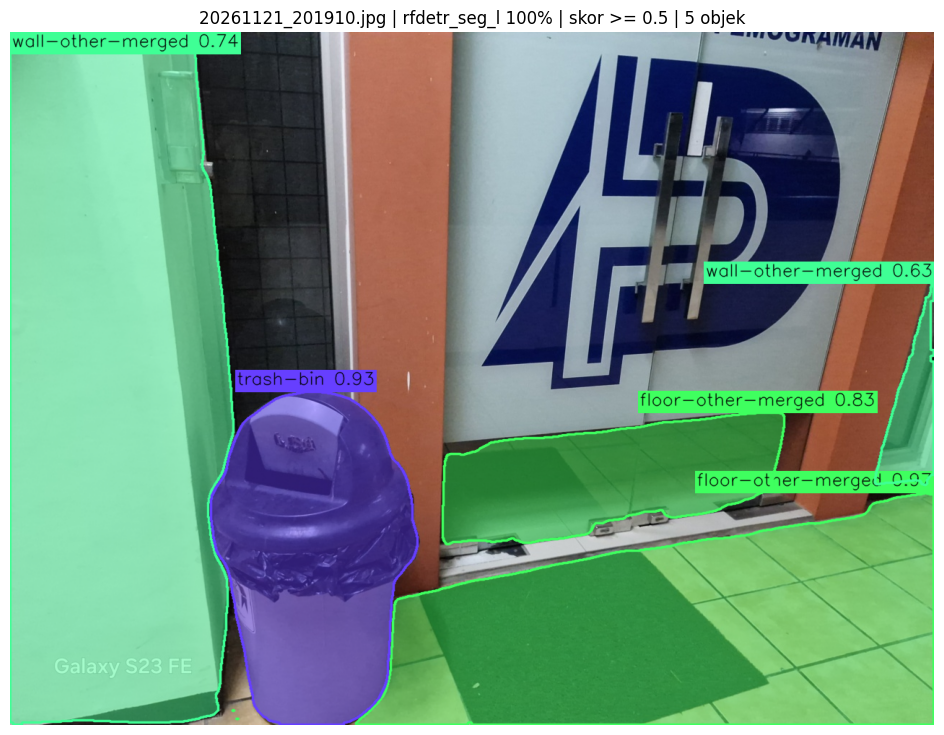

,kelas,skor,luas_px
0,floor-other-merged,0.968,186927
1,trash-bin,0.929,99742
2,floor-other-merged,0.829,60338
3,wall-other-merged,0.735,273908
4,wall-other-merged,0.630,12014


gambar tersimpan di demo/outputs/rfdetr_seg_l_split100_conf0.5


In [65]:
assert globals().get("PRED_MODEL") == (MODEL, SPLIT), "MODEL/SPLIT berubah: jalankan sel 3 dan 4 dulu"
check_classes(SHOW_CLASSES, "SHOW_CLASSES")

out_dir = HERE / "outputs" / f"{MODEL}_split{SPLIT}_conf{CONF_THRESH}"
out_dir.mkdir(parents=True, exist_ok=True)
for img_path, preds in PREDS.items():
    keep = [p for p in preds if p["score"] >= CONF_THRESH
            and (not SHOW_CLASSES or NAMES[p["category_id"] - 1] in SHOW_CLASSES)]
    drawn = draw_predictions(cv2.imread(str(img_path)), keep)
    cv2.imwrite(str(out_dir / img_path.name), drawn)

    plt.figure(figsize=(12, 9))
    plt.imshow(drawn[..., ::-1])  # BGR (OpenCV) -> RGB (matplotlib)
    plt.title(f"{img_path.name} | {MODEL} {SPLIT}% | skor >= {CONF_THRESH} | {len(keep)} objek")
    plt.axis("off")
    plt.show()
    rows = [{"kelas": NAMES[p["category_id"] - 1], "skor": round(p["score"], 3), "luas_px": int(p["mask"].sum())}
            for p in keep]
    display(pd.DataFrame(rows, columns=["kelas", "skor", "luas_px"]).sort_values("skor", ascending=False))
print("gambar tersimpan di", out_dir.relative_to(ROOT))

## 6. AP satu kelas


In [66]:
check_classes([AP_CLASS], "AP_CLASS")
assert AP_TEST_SET in ("own", "original"), 'AP_TEST_SET harus "own" atau "original"'

rows = []
for m in MODELS:
    for f in SPLITS:
        pc = pd.read_csv(EVAL_DIR / f"results_{AP_TEST_SET}_test" / f"split_{C.pct(f)}" / m / "per_class_ap.csv")
        r = pc.loc[pc["name"] == AP_CLASS].iloc[0]
        rows.append({"model": m, "split": C.pct(f), "num_gt": int(r["num_gt"]), "AP": r["AP"], "AP50": r["AP50"]})
ap = pd.DataFrame(rows)

n_gt = ap["num_gt"].iloc[0]
print(f"kelas '{AP_CLASS}': {n_gt} instance di test set {AP_TEST_SET}")
if n_gt == 0:
    print("kelas ini tidak ada di test set ini, AP tidak terdefinisi. Coba AP_TEST_SET yang lain.")
else:
    cur = ap[(ap.model == MODEL) & (ap.split == SPLIT)].iloc[0]
    print(f"{MODEL} {SPLIT}%: AP = {cur.AP:.3f}, AP50 = {cur.AP50:.3f}")
    for metric in ("AP", "AP50"):
        print(f"\n{metric} (baris = model, kolom = % data latih)")
        display(ap.pivot(index="model", columns="split", values=metric).round(3))

kelas 'chair': 47 instance di test set own
rfdetr_seg_l 100%: AP = 0.167, AP50 = 0.339

AP (baris = model, kolom = % data latih)


split,25,50,100
model,,,
maskrcnn_r50_fpn,0.054,0.076,0.135
rfdetr_seg_l,0.191,0.191,0.167
yolo26l_seg,0.051,0.053,0.142



AP50 (baris = model, kolom = % data latih)


split,25,50,100
model,,,
maskrcnn_r50_fpn,0.131,0.203,0.329
rfdetr_seg_l,0.326,0.341,0.339
yolo26l_seg,0.125,0.129,0.259
